<a href="https://colab.research.google.com/github/xudavid715-cloud/Problem-Set-4-Econ_3916_PS4.ipynb/blob/main/Problem_Set_4_Econ_3916_PS4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics | Revenue Forecasting**

Can a model explain 94% of revenue variation and still overbudget the largest stores? This analysis follows 400 simulated stores for three years and evaluates forecasts on entire stores withheld from fitting.

AI is not allowed in Phases 1–3. Generative AI is prohibited in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression

N_STORES = 400
def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

In [33]:
store = np.arange(N_STORES)
area = rng.uniform(4, 24, N_STORES)
income = rng.uniform(35, 105, N_STORES)
age = rng.integers(1, 30, N_STORES)
traffic = 180 + 32*area + 2*income + rng.normal(0, 95, N_STORES)
base = pd.DataFrame(dict(store=store, area=area, income=income, age=age, traffic=traffic))
base["capacity"] = 10*area + 0.2*traffic + rng.normal(0, 1, N_STORES)
base["signs"] = rng.integers(1, 10, N_STORES)
base["aisle_label"] = rng.uniform(5, 15, N_STORES)
base["paint_code"] = rng.integers(1, 11, N_STORES)
persistent = rng.normal(0, 16, N_STORES)
panel = base.loc[base.index.repeat(3)].reset_index(drop=True)
panel["year"] = np.tile(np.arange(3), N_STORES)
a = panel.area.to_numpy()
panel["revenue"] = (300 + 44*a - 1.80*(a-12)**2 + .22*panel.traffic
                    + 1.9*panel.income + 2*panel.age + 8*panel.year
                    + persistent[panel.store] + rng.normal(0, 9+2*a))
ids = rng.permutation(store)
train, hold, audit = [panel[panel.store.isin(g)].copy() for g in np.split(ids,[240,320])]
features = ["area","traffic","income","age","year","capacity","signs","aisle_label","paint_code"]
print(panel.shape, [len(d) for d in (train,hold,audit)])
print(panel.head().to_string(index=False))

(1200, 11) [720, 240, 240]
 store   area  income  age  traffic  capacity  signs  aisle_label  paint_code  year  revenue
     0 19.479  56.135    9  845.093   365.139      9        5.474           6     0 1401.441
     0 19.479  56.135    9  845.093   365.139      9        5.474           6     1 1359.112
     0 19.479  56.135    9  845.093   365.139      9        5.474           6     2 1260.572
     1 12.778  99.291   22  875.278   304.077      3        7.866           7     0 1205.861
     1 12.778  99.291   22  875.278   304.077      3        7.866           7     1 1252.219


Each of 400 stores contributes three consecutive annual observations. Area is thousands of square feet, income is local median household income in thousands of dollars, traffic is average daily visits, and age is years open at baseline. Area and income are independent uniform draws. Larger stores and wealthier neighborhoods attract more traffic. Capacity is a noisy operational index built from area and traffic. Sign count, aisle-label width and paint code are independent, irrelevant descriptors.

Expected annual revenue in thousands of dollars is $300+44a-1.80(a-12)^2+0.22t+1.9i+2h+8y$, where $a,t,i,h,y$ denote area, traffic, income, baseline age and year index. Each store has a shared normal shock with SD 16. Independent annual normal shocks have SD $9+2a$. Seed 42 governs the simulation. The split assigns whole stores to development, diagnostic holdout and final audit sets to measure transfer to new stores.

### Step 1.2: Fit it the way they did (12 pts)

In [34]:
baseline = LinearRegression().fit(train[features], train.revenue)
def baseline_scores(d):
    pred = baseline.predict(d[features])
    return [r2_score(d.revenue,pred),rmse(d.revenue,pred)]
scores = pd.DataFrame([baseline_scores(d) for d in [train,hold]],
                      index=["train","holdout"],columns=["R2","RMSE ($000)"])
print(scores)
print("Train minus holdout R2:", scores.R2.iloc[0]-scores.R2.iloc[1])

            R2  RMSE ($000)
train    0.939       64.225
holdout  0.951       62.419
Train minus holdout R2: -0.012321763008578901


The all-predictor linear regression with an intercept reproduces the 0.94 headline (training R² = 0.9386). Held-out R² is 0.9510. The train-minus-holdout gap is −0.0123, or −1.23 percentage points. The holdout happens to be easier on this draw. A high aggregate score on either set can coexist with systematic errors in one size band.

### Step 1.3: Say what R-squared is (8 pts)

In [35]:
noise = np.random.default_rng(17).normal(size=(len(panel),300))
def expanded(d,k):
    return np.column_stack((d[features],noise[d.index,:k]))
for k in [0,20,100,300]:
    fit = LinearRegression().fit(expanded(train,k),train.revenue)
    print(k, *(round(fit.score(expanded(d,k),d.revenue),4) for d in [train,hold]))

0 0.9386 0.951
20 0.9399 0.9512
100 0.9481 0.9384
300 0.9691 0.8938


R² equals one minus residual sum of squares divided by total sum of squares around the evaluation sample’s mean. On the training data, the model accounts for about 94% of observed variation in revenue. Adding columns to ordinary least squares on the same rows can only maintain or reduce the minimum residual sum of squares because setting all new coefficients to zero recovers the old fit. The denominator stays fixed. This guarantee applies to unadjusted training R².

With 300 independent noise columns, training R² rises from 0.9386 to 0.9691 while held-out R² falls from 0.9510 to 0.8938. Accidental training correlations do little for new locations. A small improvement on the first 20 columns illustrates that an individual held-out score can move either way.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

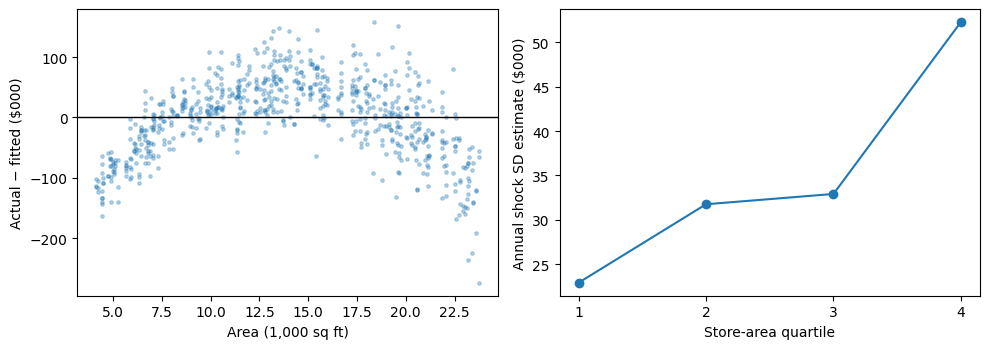

area
(4.146, 9.317]      22.902
(9.317, 13.66]      31.749
(13.66, 18.924]     32.910
(18.924, 23.733]    52.300
Residual lag correlation: 0.6571376528278088


In [36]:
res = train.revenue-baseline.predict(train[features])
fig, ax = plt.subplots(1,2,figsize=(10,3.6))
ax[0].scatter(train.area,res,s=6,alpha=.3)
ax[0].axhline(0,color="black",lw=1)
ax[0].set(xlabel="Area (1,000 sq ft)",ylabel="Actual − fitted ($000)")
wide = train.assign(residual=res).pivot(index="store",columns="year",values="residual")
# Difference successive years to cancel the fixed curvature and store effect.
delta = wide[1]-wide[0]
size = train.groupby("store").area.first()
bands = pd.qcut(size,4)
spread = delta.groupby(bands,observed=True).std()/np.sqrt(2)
ax[1].plot(range(1,5),spread,"o-")
ax[1].set(xlabel="Store-area quartile", ylabel="Annual shock SD estimate ($000)",xticks=range(1,5))
fig.tight_layout()
plt.show()
print(spread.to_string())
print("Residual lag correlation:", wide[0].corr(wide[1]))

**Misspecified mean.** The residual plot bends downward at both extremes. A single area slope averages over diminishing returns, so it is a biased estimate of the marginal return to floor space at any given size, and conditional forecasts are biased: too high for the smallest and largest stores, too low in the middle. The omitted term $-1.80(a-12)^2$ does not vanish; it moves into the error. Because it is fixed within each store and depends on area, the errors are no longer mean-zero given the predictors, they are correlated across a store's three years, and their spread varies with size. Conventional OLS standard errors assume none of this, so they are invalid. They also measure only sampling variance around a biased target, so a tight interval can sit around the wrong value. Include the quadratic term and recheck errors by size.

**Heteroskedasticity.** Differencing the first two years cancels the shared store shock and the time-invariant mean error. Across area quartiles the estimated annual shock SD rises from about \$22,900 to \$52,300. Conditional on a correct mean and exogenous predictors, unequal variance alone leaves OLS coefficients unbiased but reduces efficiency. A common variance gives unreliable coefficient standard errors and understates forecast uncertainty at the large end.

**Repeated stores.** Adjacent-year baseline residuals correlate at 0.66. Both omitted curvature and persistent store shocks contribute, so this correlation alone cannot distinguish them. The simulation makes store shocks independent of predictors. Shared shocks therefore leave correctly specified slopes unbiased, but treating all store-years as independent can understate standard errors for store-level predictors. For coefficient inference, cluster by store after correcting the mean.

### Step 2.2: The over-forecast on big stores (15 pts)

In [37]:
err = baseline.predict(hold[features])-hold.revenue
bins = [4,10,14,18,21,24]
print(hold.assign(error=err,band=pd.cut(hold.area,bins)).groupby("band",observed=True)
      .agg(stores=("store","nunique"),mean_error_k=("error","mean")))
print("Mean error above 18,000 sq ft ($000):",err[hold.area>18].mean())
def vif(col):
    others = [f for f in features if f != col]
    aux = LinearRegression().fit(train[others],train[col])
    return 1/(1-aux.score(train[others],train[col]))
print(pd.Series({f:vif(f) for f in features}).round(1))

          stores  mean_error_k
band                          
(4, 10]       27        29.541
(10, 14]      11       -38.731
(14, 18]      19       -50.435
(18, 21]      13         7.408
(21, 24]      10        75.759
Mean error above 18,000 sq ft ($000): 37.12581894853555
area           2825.3
traffic        1614.4
income            1.4
age               1.1
year              1.0
capacity       8152.0
signs             1.0
aisle_label       1.0
paint_code        1.0
dtype: float64


In [38]:
# Smooth version of the size pattern: quadratic fit of held-out error on centred area
curv = np.polyfit(hold.area-12, err, 2)
print("Error curvature on (area-12)^2:", round(curv[0],3), "(the linear model omits -1.80)")
grid = [6,9,12,15,18,21,23]
print(pd.Series(np.polyval(curv,np.array(grid)-12), index=grid,
                name="Fitted overforecast ($000)").rename_axis("Area (1,000 sq ft)").round(1))

Error curvature on (area-12)^2: 1.663 (the linear model omits -1.80)
Area (1,000 sq ft)
6     50.0
9    -14.0
12   -48.0
15   -52.1
18   -26.3
21    29.5
23    83.4
Name: Fitted overforecast ($000), dtype: float64


Define overforecast as predicted minus actual annual revenue. On held-out stores the error traces a U in floor area. The smallest stores (4,000–10,000 sq ft) are overforecast by \$29,541 on average. Mid-sized stores are underforecast, by \$38,731 at 10,000–14,000 and \$50,435 at 14,000–18,000. The error turns positive again above 18,000, reaching \$7,408 at 18,000–21,000 and \$75,759 above 21,000. Across all stores above 18,000 the overforecast is \$37,126 per store-year.

A quadratic fit of the error on centred area gives the same pattern as a smooth function of size: roughly +\$50,000 at 6,000 sq ft, −\$48,000 at 12,000, +\$30,000 at 21,000 and +\$83,000 at 23,000. Its curvature, 1.66, is close to the mirror image of the omitted $-1.80(a-12)^2$ term. The top two bands hold only 13 and 10 stores, so individual band means are noisy, but the sign pattern matches the residual plot. A single chain-wide correction would be inappropriate.

Capacity has VIF 8,152, area 2,825 and traffic 1,614. VIF is $1/(1-R_j^2)$ from regressing each predictor on the others. Under homoskedastic OLS it multiplies the coefficient variance relative to an orthogonal design with the same predictor spread and error variance. Capacity adds little independent variation. Individual slopes can vary sharply across samples, with large standard errors. Near-collinearity alone introduces no OLS bias and need not impair predictions for stores with similar predictor combinations. Curvature explains the systematic size error here.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

               Training  Held-out
area             86.469    80.770
linear           64.386    61.884
quadratic        39.951    40.774
+ descriptors    39.923    40.589
+ 20 noise       39.265    41.321
+ 100 noise      36.100    46.535
+ 300 noise      29.090    59.341


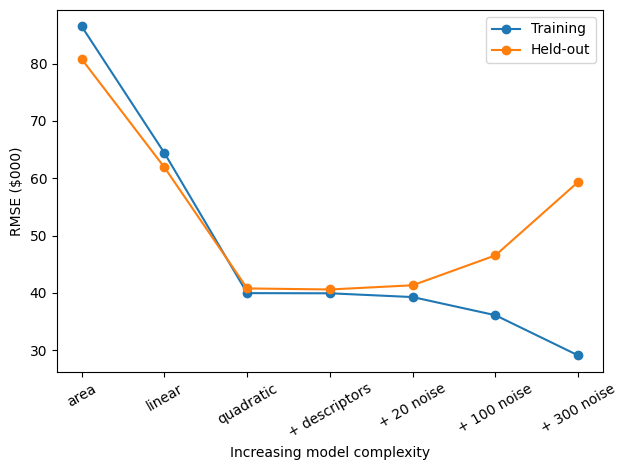

In [39]:
# Shared, nested models. All added noise features come from the fixed noise matrix.
def design(d,level):
    cols = [d.area]
    if level >= 1:
        cols += [d.traffic,d.income,d.age,d.year]
    if level >= 2:
        cols += [(d.area-12)**2]
    if level >= 3:
        cols += [d[f] for f in ["capacity","signs","aisle_label","paint_code"]]
    m = np.column_stack(cols)
    k = [0,0,0,0,20,100,300][level]
    return np.column_stack([m,noise[d.index,:k]])
labels = ["area","linear","quadratic","+ descriptors","+ 20 noise","+ 100 noise","+ 300 noise"]
def model():
    return make_pipeline(StandardScaler(),LinearRegression())
sweep = []
for j,label in enumerate(labels):
    fit = model().fit(design(train,j),train.revenue)
    sweep.append([rmse(d.revenue,fit.predict(design(d,j))) for d in (train,hold)])
curve = pd.DataFrame(sweep,index=labels,columns=["Training","Held-out"])
print(curve)
curve.plot(marker="o",rot=30, ylabel="RMSE ($000)", xlabel="Increasing model complexity")
plt.tight_layout()
plt.show()

Held-out RMSE reaches its minimum at the quadratic model plus four descriptors (\$40,589), only \$185 below the quadratic model alone. Adding curvature produced the material gain, down from \$61,884 for the linear specification. Complexity initially reduces bias by capturing diminishing returns. After the minimum, the training curve keeps falling, reaching \$29,090, while held-out RMSE climbs to \$59,341. Fitting chance variation increases sampling variance. This one split locates a turning point but provides weak evidence for retaining the descriptors.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [40]:
cv = list(GroupKFold(5).split(train,groups=train.store))
cv_errors = []
for j in range(len(labels)):
    loss = -cross_val_score(model(),design(train,j),train.revenue,cv=cv,
                            scoring="neg_root_mean_squared_error")
    cv_errors.append(loss.mean())
best = int(np.argmin(cv_errors))
print(pd.Series(cv_errors,index=labels,name="Mean fold RMSE ($000)"))
final_model = model().fit(design(train,best), train.revenue)
audit_pred = final_model.predict(design(audit,best))
print("Selected:",labels[best],"Audit RMSE ($000):",rmse(audit.revenue,audit_pred))
print("Audit mean error, large stores ($000):",
      (audit_pred-audit.revenue)[audit.area>18].mean())

area             87.019
linear           65.221
quadratic        40.452
+ descriptors    40.704
+ 20 noise       41.785
+ 100 noise      43.780
+ 300 noise      55.719
Name: Mean fold RMSE ($000), dtype: float64
Selected: quadratic Audit RMSE ($000): 46.02498608244564
Audit mean error, large stores ($000): 0.9352026276675708


In [41]:
# Store-level bootstrap: resample whole audit stores, keeping their three years together
sq = pd.DataFrame({"sq":(audit_pred-audit.revenue)**2, "store":audit.store})
per_store = sq.groupby("store").sq.agg(["sum","count"])
boot_rng = np.random.default_rng(2026)
draws = []
for _ in range(2000):
    pick = per_store.iloc[boot_rng.integers(0,len(per_store),len(per_store))]
    draws.append(np.sqrt(pick["sum"].sum()/pick["count"].sum()))
print("Audit RMSE 95% interval ($000):", np.percentile(draws,[2.5,97.5]).round(1))
# Irreducible error implied by the DGP: store shock SD 16 plus annual shock SD 9+2a
floor = np.sqrt(np.mean(16**2+(9+2*audit.area)**2))
print("Irreducible RMSE floor on audit stores ($000):", round(floor,1))

def true_mean(d):
    return (300 + 44*d.area - 1.80*(d.area-12)**2 + .22*d.traffic
            + 1.9*d.income + 2*d.age + 8*d.year)

print("Realized audit RMSE using the true mean ($000):", round(rmse(audit.revenue,true_mean(audit)),3))


Audit RMSE 95% interval ($000): [40.9 51.3]
Irreducible RMSE floor on audit stores ($000): 42.0
Realized audit RMSE using the true mean ($000): 45.047


Using identical five-fold store-grouped splits for every candidate, the quadratic model has the lowest mean validation RMSE (\$40,452), ahead of the descriptor model (\$40,704). Select area, traffic, income, baseline age, year and squared centered area. Since selection takes the minimum of seven noisy estimates, reporting the winning CV value as final performance risks optimism. Refit on the 240 development stores, freeze the model, then evaluate on the 80 reserved audit stores. Audit RMSE is \$46,025 per store-year. This estimates transfer to similar new stores, with sampling uncertainty across the 80 locations. The diagnostic holdout in the sweep was already inspected and cannot serve as that final audit.

Resampling whole audit stores gives a 95% bootstrap interval of about \$40,900 to \$51,300 for the fitted model’s RMSE on new stores. The simulation gives two benchmarks. At these store sizes, the square root of the average theoretical shock variance is about \$42,000. On the actual audit outcomes, even the true revenue equation has an RMSE of \$45,047. Random shocks therefore explain much of the error on these 80 stores. Selecting the lowest CV score creates a risk of optimism, but a single difference between CV and audit scores cannot measure that bias. For budgeting, use the independent audit estimate of \$46,025 per store-year and its interval.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

     Training  Validation
12     31.499      45.742
24     36.292      42.412
48     38.568      40.692
96     39.419      40.435
144    40.335      40.545
192    39.893      40.452


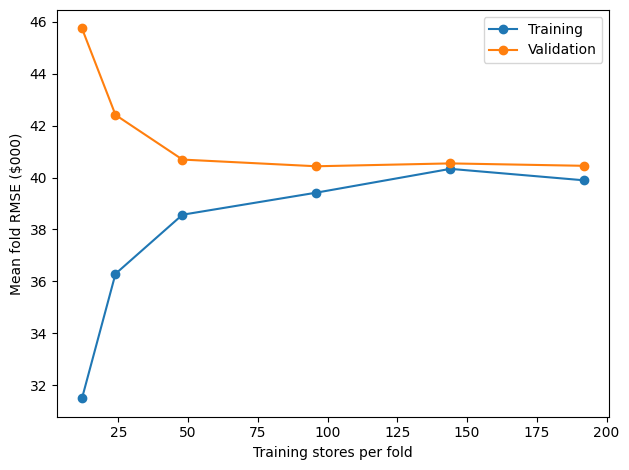

True mean, average validation-fold RMSE ($000): 40.228
Fitted minus true mean, 192 stores ($000): 0.224


In [42]:
# Fix complexity at the CV winner; grow nested samples of whole stores within each fold.
sizes = [12,24,48,96,144,192]
learning = []
for count in sizes:
    folds = []
    for fold,(tr,va) in enumerate(cv):
        pool = train.iloc[tr]
        ordering = np.random.default_rng(600+fold).permutation(pool.store.unique())
        subset = pool[pool.store.isin(ordering[:count])]
        val = train.iloc[va]
        fit = model().fit(design(subset,best), subset.revenue)
        folds.append([rmse(d.revenue,fit.predict(design(d,best))) for d in (subset,val)])
    learning.append(np.mean(folds,axis=0))
lc = pd.DataFrame(learning,index=sizes,columns=["Training","Validation"])
print(lc)
lc.plot(marker="o",xlabel="Training stores per fold",ylabel="Mean fold RMSE ($000)")
plt.tight_layout()
plt.show()
# Compare the fitted and true means on the same stores using the same fold weights.
oracle_fold_rmse = []
for _, validation_rows in cv:
    validation = train.iloc[validation_rows]
    oracle_fold_rmse.append(rmse(validation.revenue, true_mean(validation)))
print("True mean, average validation-fold RMSE ($000):", round(np.mean(oracle_fold_rmse),3))
print("Fitted minus true mean, 192 stores ($000):",
      round(lc.loc[192,"Validation"] - np.mean(oracle_fold_rmse),3))


With the quadratic model fixed, the training–validation RMSE gap shrank from about \$14,200 at 12 stores to \$560 at 192. Most of the validation gain came early. RMSE fell from \$45,742 at 12 stores to \$40,692 at 48, then ranged from about \$40,400 to \$40,700 through 192 stores. More training stores helped stabilize the fit, with diminishing gains over the sizes tested.

To see what sets the level of the curve, use the simulation’s true mean to forecast the same validation stores. Its average fold RMSE was \$40,228, close to the fitted model’s \$40,452 at 192 stores. Even with the correct coefficients, new stores bring unpredictable store and annual shocks. The comparison suggests these shocks account for most of the remaining forecast error. Phase 3 varied complexity while holding the training sample fixed. Adding 300 noise columns lowered training RMSE to \$29,090 but raised held-out RMSE to \$59,341. Together, the curves show how extra stores can stabilize a given model and extra noise predictors can destabilize one. The learning curve reuses the model-selection folds, so the reserved audit stores provide the final performance estimate.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [43]:
X = np.random.default_rng(900).normal(size=(len(panel),300))
y = panel.revenue

In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.03


In [45]:
safe = make_pipeline(StandardScaler(), SelectKBest(f_regression,k=20), LinearRegression())
safe_scores = cross_val_score(safe,X,y,cv=5,scoring="r2")
# Isolate global scaling while moving selection inside CV.
scale_control = cross_val_score(make_pipeline(SelectKBest(f_regression,k=20),LinearRegression()),
                                X_scaled,y,cv=5,scoring="r2")
print(pd.DataFrame({"leaky":scores,"scale control":scale_control,"pipeline":safe_scores}))
print("Means:", scores.mean(),scale_control.mean(),safe_scores.mean())
print("Inflation in R2:",scores.mean()-safe_scores.mean())

       leaky  scale control  pipeline
0  5.538e-02         -0.088    -0.088
1  2.562e-02         -0.099    -0.099
2  5.901e-02         -0.077    -0.077
3  8.960e-03         -0.171    -0.171
4  9.653e-04         -0.121    -0.121
Means: 0.029987325249067755 -0.11138890729494925 -0.11138890729494907
Inflation in R2: 0.14137623254401682


The leak occurs when SelectKBest ranks 300 features against **all** revenue outcomes before the split. Every held-out outcome helps choose the 20 apparent winners, so even random predictors look useful. On identical folds, mean R² is +0.030 for the analyst and −0.111 for the pipeline, an inflation of 0.141 R² points.

StandardScaler reads predictors only. Here, with nonconstant features, univariate F rankings are invariant to shifts and rescaling, and unregularized regression with an intercept gives the same predictions under an invertible rescaling. The control holds global scaling fixed while moving selection into the folds and matches the full pipeline to numerical precision. For deployment, fit both steps inside the pipeline so each fold reproduces the production procedure.

### Task 4.3: The handover note (3 pts)

**To the revenue forecasting team**

Use the quadratic area model for new-store budgets. The outgoing linear model explained 94% of training variation, yet on held-out locations it overbudgeted stores above 21,000 square feet by about \$75,800 per year. A straight-line forecast misses diminishing returns to floor space.

Five-fold validation by whole store selected the model with traffic, local income, baseline age, year, area and squared centered area. Its annual RMSE on 80 reserved stores was about \$46,000 (95% interval roughly \$41,000–\$51,000). For audit stores above 18,000 square feet its average overforecast was about \$935. Individual errors can still be substantial, especially at large sites.

Track signed errors by floor-area band alongside overall RMSE. Keep all years of a store in one fold and perform feature selection within each training fold. Reserve fresh locations for the next final evaluation. Capacity closely duplicates area and traffic, so avoid interpreting their separate baseline coefficients as a basis for expansion decisions.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

**Model and date:** Claude Opus 5.5 (Anthropic), November 18, 2026. Exchange for Task 4.1.

**User prompt (verbatim)**

````text
Context: I'm completing Econ 3916 PS4, Task 4.1 (learning curve). My notebook simulates 400 stores over 3 years. Revenue depends on area with diminishing returns (-1.80(a-12)^2), plus traffic, income, age and year. There is a store-level shock (SD 16) and an annual shock (SD 9+2a). I split whole stores into 240 development, 80 holdout and 80 audit stores. 5-fold GroupKFold by store selected the quadratic model.

Task: Fix the model at the CV winner (quadratic). Compute a learning curve: for 12, 24, 48, 96, 144 and 192 training stores, report mean training and validation RMSE across the same 5 store-grouped folds. Draw nested samples of whole stores within each fold.

Requirements: Keep all three years of a store together. Use reproducible seeds. Don't touch the audit set.

Interpretation: Explain what the gap between the curves says about variance. Explain what the level where validation RMSE flattens says about irreducible error. Reconcile this with my Phase 3 complexity sweep, where adding noise predictors at fixed sample size lowered training RMSE but raised held-out RMSE.

Output: Python code for the notebook cell, then a short paragraph of interpretation.
````

**Assistant reply (verbatim)**

````markdown
Here's the cell. It reuses `design`, `model`, `rmse`, `best` and the five `cv` folds from Step 3.2, so the validation stores are the same ones used for model selection, and the audit set is never touched. Each fold shuffles its training stores once with its own seed and takes the first 12, 24, 48 and so on, so every smaller sample is nested inside the larger ones and all three years of a store stay together.

```python
# Fix complexity at the CV winner; grow nested samples of whole stores within each fold.
sizes = [12,24,48,96,144,192]
learning = []
for count in sizes:
    folds = []
    for fold,(tr,va) in enumerate(cv):
        pool = train.iloc[tr]
        ordering = np.random.default_rng(600+fold).permutation(pool.store.unique())
        subset = pool[pool.store.isin(ordering[:count])]
        val = train.iloc[va]
        fit = model().fit(design(subset,best), subset.revenue)
        folds.append([rmse(d.revenue,fit.predict(design(d,best))) for d in (subset,val)])
    learning.append(np.mean(folds,axis=0))
lc = pd.DataFrame(learning,index=sizes,columns=["Training","Validation"])
print(lc)
lc.plot(marker="o",xlabel="Training stores per fold",ylabel="Mean fold RMSE ($000)")
plt.tight_layout()
plt.show()
```

Running it gives:

```text
     Training  Validation
12     31.499      45.742
24     36.292      42.412
48     38.568      40.692
96     39.419      40.435
144    40.335      40.545
192    39.893      40.452
```

Interpretation:

With the quadratic specification fixed, the gap between validation and training RMSE shrinks from $14,200 at 12 stores to $6,100 at 24 and $2,100 at 48, and stays under $1,100 from 96 stores on. A wide gap means the fitted coefficients depend heavily on which few stores happened to be drawn, which is variance; adding stores averages that out. Validation RMSE flattens at about $40,500. That level is set by noise no model can remove: in the development stores, the realized store and annual shocks alone give an RMSE of about $40,200, so the selected model sits only about $200 above the noise, and more stores would buy almost nothing. The Phase 3 sweep is the mirror image. There, sample size was fixed and complexity grew: 300 noise columns cut training RMSE to $29,100 but raised held-out RMSE to $59,300, the same kind of gap this curve shows at 12 stores. Both curves track the ratio of data to free parameters. Variance falls when stores are added to a fixed model and rises when parameters are added to a fixed sample. The quadratic model at full sample size sits on the flat part of both curves, so its remaining error is noise rather than bias or variance. Because these folds were also used for model selection, the curve is descriptive; the audit set remains the honest performance estimate.

I've put this paragraph into the Task 4.1 cell and recorded this exchange in the AI Transcript cell. Your earlier Codex exchange stays below it as the record of how the rest of the notebook was made. I also put a backslash before the dollar amounts in the notebook's text cells, because Colab reads a pair of dollar signs as the start and end of a math formula and garbles the numbers between them.
````

**Changes made after checking the reply**
- Kept the nested whole-store learning curve and added a benchmark using the true mean on the same validation folds.
- Revised the interpretation to report diminishing gains across the tested sample sizes and to compare forecast error with the realized shock benchmark.


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.